**Related files**

| File | Role |
|------|------|
| `titanic_20261027_01.ipynb` | **This notebook.** Original notebook: baseline models |
| `titanic_20261027_01_review1.md` | Review of this notebook: bugs, smarter code and English |
| `titanic_20261027_01_claude1.ipynb` | Cleaned-up version of this notebook, based on review1 (same CV scores, XGBoost bug fixed) |

Flow: 01 → review1 → 01_claude1

## 0. Contents

## 1. Setup

In [1]:
import os, time, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "8"
#warnings.filterwarnings("ignore")

import sys
sys.path.append(r"../mylib")
sys.path.append(r"./mylib")    # GitHub: mylib/ sits next to this notebook
from myutils import mk_fname, sep, style  # pyright: ignore[reportMissingImports]

# _/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from xgboost  import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold


DATA_DIR    = "./data/titanic"

TRAIN_PATH  = os.path.join(DATA_DIR, "train.csv")  #  TRAIN_PATH = f"{DATA_DIR}/train.csv" is also available
TEST_PATH   = os.path.join(DATA_DIR, "test.csv")
SAMPLE_PATH = os.path.join(DATA_DIR, "gender_submission.csv")
OUT_DIR     = os.path.join(DATA_DIR, "output")
os.makedirs(OUT_DIR, exist_ok = True)

TARGET = "Survived"
ID     ="PassengerId"

RANSEED = 42

CV          = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANSEED)
#from sklearn.model_selection import RepeatedStratifiedKFold
#CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANSEED)   # 25 fold
SCORING = "accuracy"

N_TREES      = 500      # RandomForest
N_BOOST      = 100      # LightGBM / HGB
LR_MAX_ITER  = 1000     # LogisticRegression solver
HGB_MAX_ITER = 1000    # HistGradientBoost
N_CAT       = 200      # Cat boost
LEARNING_RATE = 0.15

is_RF_base  = True
is_LR_base  = True
is_HGB_base = True
is_LGB_base = True
is_XGB_base = True
is_CAT_base = True

is_MK_SUBMISSION = False

is_TEST = False


# HGB_PARAMS = {} works as well
HGB_PARAMS = dict(
    learning_rate=LEARNING_RATE,
    max_iter=HGB_MAX_ITER,      # upper limit; early stopping decides the actual number
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=RANSEED,
    max_leaf_nodes = 15,      # candidates: 15, 31, 63, 127
    min_samples_leaf = 20,    # 20, 100, 200
)






# Just for my study
import lightgbm as lgb
import xgboost as xgb
import catboost as catb
print("Pandas:   ", pd.__version__)
print("Numpy:    ", np.__version__)
print("LightGBM: ", lgb.__version__)
print("XGBoost:  ", xgb.__version__)
print("CatBoost: ", catb.__version__)


Pandas:    2.2.3
Numpy:     2.1.3
LightGBM:  4.7.0
XGBoost:   3.4.1
CatBoost:  1.2.10


#### 1.1. Data Load

In [2]:
# Never change original data 0 series
train_0  = pd.read_csv(TRAIN_PATH)
test_0   = pd.read_csv(TEST_PATH)
sample_0 = pd.read_csv(SAMPLE_PATH)

train  = train_0.copy()
test   = test_0.copy()
sample = sample_0.copy()

# check whether submission sample is the same as test.csv
assert (sample[ID].values == test[ID].values).all()  

#### 1.2. Survey data overview

In [3]:
print("train.shape: ", train.shape, "| test.shape: ", test.shape)
sep()
print("train.head(3):")
display(train.head(3))
sep()
print("train.describes()")
display(train.describe())
sep()
print("train.dtypes:")
print(train.dtypes)

train.shape:  (891, 12) | test.shape:  (418, 11)
_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/
train.head(3):


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/
train.describes()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/
train.dtypes:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


#### 1.3. Survey missing data

In [4]:
def missing(df):
    return pd.DataFrame({
        "dtype":         df.dtypes.astype(str),
        "missing":       df.isna().sum(),
        "missing_ratio": df.isna().mean().round(3) * 100,
        "n_unique":      df.nunique(dropna=True),
    })

missing_table = pd.concat(
    {"train": missing(train), "test": missing(test)},
    axis=1,
).sort_values(("train", "missing_ratio"), ascending=False)

print("Missing Table")
sep(char="-", n=15)
display(missing_table)

Missing Table
---------------


train                                    test          \
               dtype missing missing_ratio n_unique    dtype missing   
Cabin         object     687          77.1      147   object   327.0   
Age          float64     177          19.9       88  float64    86.0   
Embarked      object       2           0.2        3   object     0.0   
PassengerId    int64       0           0.0      891    int64     0.0   
Name          object       0           0.0      891   object     0.0   
Pclass         int64       0           0.0        3    int64     0.0   
Survived       int64       0           0.0        2      NaN     NaN   
Sex           object       0           0.0        2   object     0.0   
Parch          int64       0           0.0        7    int64     0.0   
SibSp          int64       0           0.0        7    int64     0.0   
Fare         float64       0           0.0      248  float64     1.0   
Ticket        object       0           0.0      681   object     0.0   

                                    
            missing_ratio n_unique  
Cabin                78.2     76.0  
Age                  20.6     79.0  
Embarked              0.0      3.0  
PassengerId           0.0    418.0  
Name                  0.0    418.0  
Pclass                0.0      3.0  
Survived              NaN      NaN  
Sex                   0.0      2.0  
Parch                 0.0      8.0  
SibSp                 0.0      7.0  
Fare                  0.2    169.0  
Ticket                0.0    363.0

> Imputing Cabin seems to be very hard but it could be useful  
> See EDA

#### 1.4. Survey survival rate ( overall)

In [5]:
survival_rate = train[TARGET].mean().round(4)
print("Survival Rate (overall): ", survival_rate)   # another way of coding: round(train[TARGET].mean(), 3))

Survival Rate (overall):  0.3838


In [6]:
# Tips something.round(3) and round(something, 3)

x = train[TARGET].mean()
print(type(x), type(x.round(3)), type(round(x, 3)))
print(x.round(3) == round(x, 3))


<class 'numpy.float64'> <class 'numpy.float64'> <class 'numpy.float64'>
True


#### 1.5 Categorize

In [7]:
# insert numerical column to list and drop ID, TARGET
num_cols = train.select_dtypes(include="number").columns.drop([ID, TARGET]).tolist()

# insert category column to list
cat_cols = train.select_dtypes(exclude="number").columns.drop(["Name"]).tolist()

print("Numerical columns: ", num_cols)
print("Category columns: ", cat_cols, "  /  Drop 'Name' since no distribution")


Numerical columns:  ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Category columns:  ['Sex', 'Ticket', 'Cabin', 'Embarked']   /  Drop 'Name' since no distribution


## 2. Make baseline

#### 2.1. Logistic Regression

In [8]:
is_Mine = False  #  False: Claude code suggestion

if is_LR_base:

    model_lr = LogisticRegression(max_iter=LR_MAX_ITER)

    y = train[TARGET]
    features = ["Pclass", "Sex", "SibSp", "Parch"]

    if is_Mine:
        # ex.1) My idea
        X = pd.get_dummies(train[features])
        X_test = pd.get_dummies(test[features])
    else:
        # ex.2) Claude suggestion
        X      = pd.get_dummies(train[features], columns=["Pclass", "Sex"])
        X_test = pd.get_dummies(test[features],  columns=["Pclass", "Sex"])
        X_test = X_test.reindex(columns=X.columns, fill_value=0)   # align columns with train
    
    scores = cross_val_score(model_lr, X, y, cv=CV, scoring=SCORING)
    print(f"Logistic Regression CV accuracy : {scores.mean():.4f} +/- {scores.std():.4f}")
    
    # for prediction
    model_lr.fit(X, y)                        # refit on all train data
    predictions = model_lr.predict(X_test)    # for submission only

    # Survival rate for predicted data
    print(f"Survival Rate (predicted): {predictions.mean():.4f}") 
    print(f"Survival Rate (actual - predicted):  {(survival_rate - predictions.mean()):.4f}")

    # make submission file
    if is_MK_SUBMISSION:   
        submission = pd.DataFrame({"PassengerId": test["PassengerId"], TARGET: predictions})   
        submit_path = os.path.join(OUT_DIR, mk_fname("submit_baseline_lr", directory=OUT_DIR))   # OUT_DIR の中で連番を確認
        submission.to_csv(submit_path, index=False)
        print("Saved:", submit_path)
        display(submission.head())
else:
    print(style("Logistic Regression for Baseline is skipped", bold=False, underline=False, color="red"))


Logistic Regression CV accuracy : 0.7969 +/- 0.0213
Survival Rate (predicted): 0.3541
Survival Rate (actual - predicted):  0.0297


> result  
ex.1) Logistic Regression CV accuracy : 0.7980 +/- 0.0235  
ex.2) Logistic Regression CV accuracy : 0.7969 +/- 0.0213


`petit test for reindex`  
When does reindex work valid

In [9]:
if is_TEST:
    a = pd.get_dummies(pd.DataFrame({"Deck": ["A", "B", "T"]}))   # train-like
    b = pd.get_dummies(pd.DataFrame({"Deck": ["A", "C"]}))        # test-like
    print(a.columns.tolist(), b.columns.tolist())
    display(b.reindex(columns=a.columns, fill_value=0))

#### 2.2. Random Forest

In [10]:
if is_RF_base:

    model_rf = RandomForestClassifier( n_estimators=100, max_depth=6, min_samples_leaf=2, random_state=RANSEED)
    y = train[TARGET]

    features = ["Pclass", "Sex", "SibSp", "Parch"]
    X = pd.get_dummies(train[features])
    X_test = pd.get_dummies(test[features])

    scores = cross_val_score(model_rf, X, y, cv=CV, scoring=SCORING)
    print(f"Random Forest CV accuracy : {scores.mean():.4f} +/- {scores.std():.4f}")

    # for prediction
    model_rf.fit(X, y)                        # refit on all train data
    predictions = model_rf.predict(X_test)    # for submission only

    # Survival rate for predicted data
    print(f"Survival Rate (predicted): {predictions.mean():.4f}") 
    print(f"Survival Rate (actual - predicted):  {(survival_rate - predictions.mean()):.4f}")
    
    # make submission file
    if is_MK_SUBMISSION:   
        submission = pd.DataFrame({"PassengerId": test["PassengerId"], TARGET: predictions})
        submit_path = os.path.join(OUT_DIR, mk_fname("submit_baseline_rf", directory=OUT_DIR))   # OUT_DIR の中で連番を確認
        submission.to_csv(submit_path, index=False)
        print("Saved:", submit_path)
        display(submission.head())
else:
    print(style("Random Forest for baseline is skipped", bold=False, underline=False, color="red"))


Random Forest CV accuracy : 0.7912 +/- 0.0171
Survival Rate (predicted): 0.3565
Survival Rate (actual - predicted):  0.0273


#### 2.3. HistGradientBoosting

In [11]:
if is_HGB_base:

    model_hgb = HistGradientBoostingClassifier(**HGB_PARAMS)

    y = train[TARGET]

    features = ["Pclass", "Sex", "SibSp", "Parch"]
    X = pd.get_dummies(train[features])
    X_test = pd.get_dummies(test[features])

    scores = cross_val_score(model_hgb, X, y, cv=CV, scoring=SCORING)
    print(f"HistGradientBoosting CV accuracy : {scores.mean():.4f} +/- {scores.std():.4f}")

    # for prediction
    model_hgb.fit(X, y)                        # refit on all train data
    predictions = model_hgb.predict(X_test)    # for submission only

    # Survival rate for predicted data
    print(f"Survival Rate (predicted): {predictions.mean():.4f}") 
    print(f"Survival Rate (actual - predicted):  {(survival_rate - predictions.mean()):.4f}")

    # make submission file
    if is_MK_SUBMISSION:   
        submission = pd.DataFrame({"PassengerId": test["PassengerId"], TARGET: predictions})
        submit_path = os.path.join(OUT_DIR, mk_fname("submit_baseline_hgb", directory=OUT_DIR))   # OUT_DIR の中で連番を確認
        submission.to_csv(submit_path, index=False)
        print("Saved:", submit_path)
        display(submission.head())
else:
    print(style("HistGradientBoosting for baseline is skipped", bold=False, underline=False, color="red"))






HistGradientBoosting CV accuracy : 0.7912 +/- 0.0121
Survival Rate (predicted): 0.3445
Survival Rate (actual - predicted):  0.0393


#### 2.4. LightGBM

In [12]:
if is_LGB_base:
    model_lgb = LGBMClassifier(
        learning_rate=LEARNING_RATE,
        n_estimators=N_BOOST,          # 早期停止が無いので本数を直接指定
        random_state=RANSEED,
        verbose=-1,
    )

    y = train[TARGET]

    features = ["Pclass", "Sex", "SibSp", "Parch"]
    X = pd.get_dummies(train[features])
    X_test = pd.get_dummies(test[features])

    scores = cross_val_score(model_lgb, X, y, cv=CV, scoring=SCORING)
    print(f"LightGBM CV accuracy : {scores.mean():.4f} +/- {scores.std():.4f}")

    # for prediction
    model_lgb.fit(X, y)                        # refit on all train data
    predictions = model_lgb.predict(X_test)    # for submission only

    # Survival rate for predicted data
    print(f"Survival Rate (predicted): {predictions.mean():.4f}") 
    print(f"Survival Rate (actual - predicted):  {(survival_rate - predictions.mean()):.4f}")

    # make submission file
    if is_MK_SUBMISSION:   
        submission = pd.DataFrame({"PassengerId": test["PassengerId"], TARGET: predictions})
        submit_path = os.path.join(OUT_DIR, mk_fname("submit_baseline_lgb", directory=OUT_DIR))   # OUT_DIR の中で連番を確認
        submission.to_csv(submit_path, index=False)
        print("Saved:", submit_path)
        display(submission.head())
else:
    print(style("LightGBM for baseline is skipped", bold=False, underline=False, color="red"))



LightGBM CV accuracy : 0.7812 +/- 0.0140
Survival Rate (predicted): 0.3565
Survival Rate (actual - predicted):  0.0273


#### 2.5. XGBoost

In [13]:
if is_XGB_base:
    model_xgb = XGBClassifier(
        learning_rate=LEARNING_RATE,
        n_estimators=N_BOOST,          # LightGBM と同じく早期停止なしなので本数を直接指定
        random_state=RANSEED,
        verbosity=0,
    )

    y = train[TARGET]

    features = ["Pclass", "Sex", "SibSp", "Parch"]
    X = pd.get_dummies(train[features])
    X_test = pd.get_dummies(test[features])

    scores = cross_val_score(model_xgb, X, y, cv=CV, scoring=SCORING)
    print(f"XGBoost CV accuracy : {scores.mean():.4f} +/- {scores.std():.4f}")

    # for prediction
    model_xgb.fit(X, y)                        # refit on all train data
    predictions = model_xgb.predict(X_test)    # for submission only  (fixed after review1: was model_lgb)

    # Survival rate for predicted data
    print(f"Survival Rate (predicted): {predictions.mean():.4f}") 
    print(f"Survival Rate (actual - predicted):  {(survival_rate - predictions.mean()):.4f}")

    # make submission file
    if is_MK_SUBMISSION:   
        submission = pd.DataFrame({"PassengerId": test["PassengerId"], TARGET: predictions})
        submit_path = os.path.join(OUT_DIR, mk_fname("submit_baseline_xgb", directory=OUT_DIR))   # OUT_DIR の中で連番を確認
        submission.to_csv(submit_path, index=False)
        print("Saved:", submit_path)
        display(submission.head())
else:
    print(style("XGBoost for baseline is skipped", bold=False, underline=False, color="red"))



XGBoost CV accuracy : 0.7834 +/- 0.0210
Survival Rate (predicted): 0.3325
Survival Rate (actual - predicted):  0.0513


#### 2.6. CatBoost

In [14]:
if is_CAT_base:
    features     = ["Pclass", "Sex", "SibSp", "Parch"]
    cat_features = ["Sex"]          # CatBoost handles categorical columns natively, so no get_dummies

    model_cat = CatBoostClassifier(
        iterations=N_CAT,
        learning_rate=LEARNING_RATE,
        random_seed=RANSEED,
        verbose=0,                   # hide per-iteration log
        allow_writing_files=False,   # don't create the catboost_info/ folder
    )                                # <- changed: cat_features removed (breaks sklearn clone)

    y = train[TARGET]
    X      = train[features]
    X_test = test[features]

    scores = cross_val_score(model_cat, X, y, cv=CV, scoring=SCORING,
                             params={"cat_features": cat_features})   # <- changed: passed to fit() in each fold
    print(f"CatBoost CV accuracy : {scores.mean():.4f} +/- {scores.std():.4f}")

    # for prediction
    model_cat.fit(X, y, cat_features=cat_features)   # <- changed: refit on all train data
    predictions = model_cat.predict(X_test)          # for submission only

    # Survival rate for predicted data
    print(f"Survival Rate (predicted): {predictions.mean():.4f}") 
    print(f"Survival Rate (actual - predicted):  {(survival_rate - predictions.mean()):.4f}")

    # make submission file
    if is_MK_SUBMISSION:   
        submission = pd.DataFrame({"PassengerId": test["PassengerId"], TARGET: predictions})
        submit_path = os.path.join(OUT_DIR, mk_fname("submit_baseline_cat", directory=OUT_DIR))   # OUT_DIR の中で連番を確認
        submission.to_csv(submit_path, index=False)
        print("Saved:", submit_path)
        display(submission.head())
else:
    print(style("CatBoost for baseline is skipped", bold=False, underline=False, color="red"))


CatBoost CV accuracy : 0.7733 +/- 0.0268
Survival Rate (predicted): 0.3493
Survival Rate (actual - predicted):  0.0345


#### 2.7. Appendix A.

> HGB has no `feature_importances_` attribute; it requires a separate technique, `permutation_importance`.   
> LogReg exposes `coef_` instead, but coefficients are not the same thing as importance and are sensitive to feature scale,   
> so they don't belong in the same table as **the three tree-based models**.

--- Feature importance (normalized) ---


,RF,LightGBM,XGBoost,CatBoost,mean
Sex,0.618,0.619,0.829,0.482,0.637
Pclass,0.218,0.254,0.122,0.249,0.211
Parch,0.083,0.072,0.024,0.136,0.079
SibSp,0.080,0.055,0.025,0.133,0.073


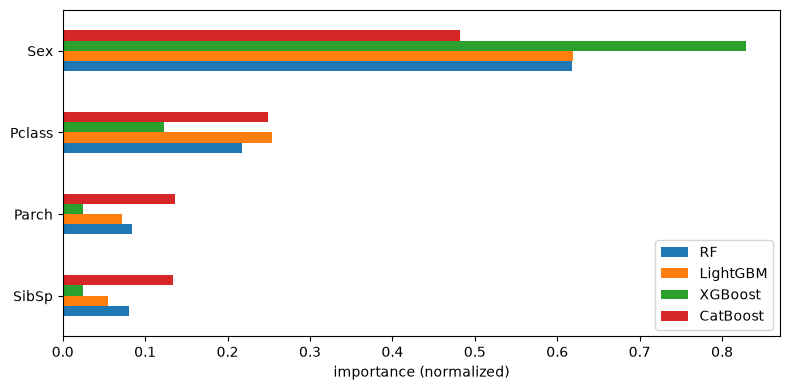

In [15]:
# --- Which features mattered most? (RF / LightGBM / XGBoost / CatBoost) ---
# LightGBM の feature_importances_ は既定で「分岐回数」なので、
# RF・XGBoost と同じ「gain（不純度の減少量）」ベースを booster_ から取り出す
# X は 2.6 で CatBoost 用 (4 列) に上書きされるため、列名は学習済みモデルから取る
importance = pd.DataFrame({
    'RF':       model_rf.feature_importances_,
    'LightGBM': model_lgb.booster_.feature_importance(importance_type='gain'),
    'XGBoost':  model_xgb.feature_importances_,
}, index=model_rf.feature_names_in_)

# CatBoost は Sex を 1 列のまま扱うので、ダミー列 (Sex_female, Sex_male) を Sex に合算して揃える
importance = importance.groupby(lambda col: col.split('_')[0]).sum()

# CatBoost の既定は PredictionValuesChange（gain ではない）。正規化すれば傾向は比較できる
importance['CatBoost'] = pd.Series(model_cat.get_feature_importance(), index=model_cat.feature_names_)

importance = importance / importance.sum()          # 列ごとに合計 1 に正規化して比較できるようにする
importance['mean'] = importance.mean(axis=1)
importance = importance.sort_values('mean', ascending=False)

print("--- Feature importance (normalized) ---")
display(importance.round(3))

ax = importance.drop(columns='mean').iloc[::-1].plot.barh(figsize=(8, 4))
ax.set_xlabel('importance (normalized)')
plt.tight_layout()
plt.show()